100%|██████████| 792M/792M [00:34<00:00, 22.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.2MB/s]


Rasmlar soni: 3680
Sinflar: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle'] ...


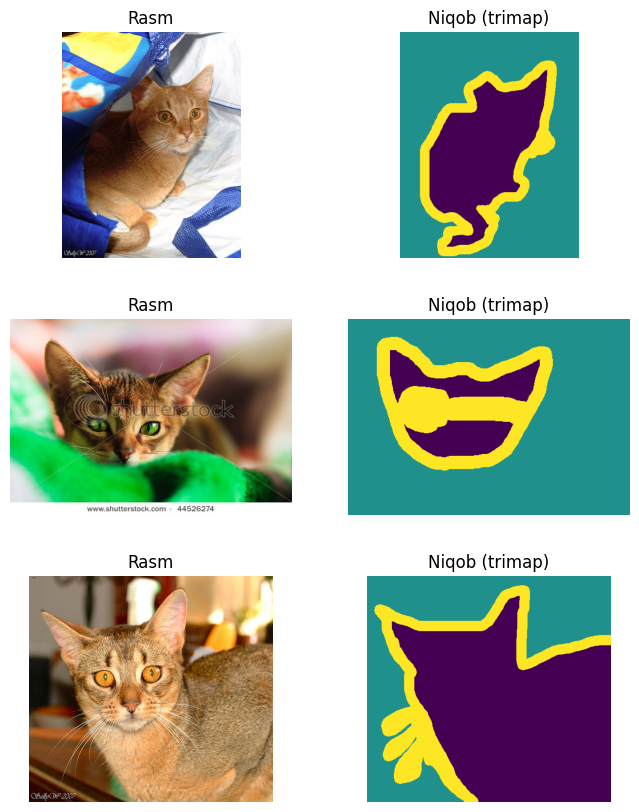

In [1]:
import torch
import matplotlib.pyplot as plt
from torchvision.datasets import OxfordIIITPet

ds = OxfordIIITPet(root="data", split="trainval",
                   target_types="segmentation", download=True)

print("Rasmlar soni:", len(ds))
print("Sinflar:", ds.classes[:5], "...")

fig, axes = plt.subplots(3, 2, figsize=(8, 10))
for i in range(3):
    img, mask = ds[i]
    axes[i, 0].imshow(img);  axes[i, 0].set_title("Rasm")
    axes[i, 1].imshow(mask); axes[i, 1].set_title("Niqob (trimap)")
    axes[i, 0].axis("off");  axes[i, 1].axis("off")
plt.show()

In [3]:
import numpy as np

sizes = set()
for i in range(50):
    img, mask = ds[i]
    sizes.add(img.size)
print("Rasm o'lchamlari (50 ta ichidan):", list(sizes)[:5])

mask = np.array(ds[0][1])
print("Niqob qiymatlari:", np.unique(mask))

Rasm o'lchamlari (50 ta ichidan): [(700, 496), (282, 450), (600, 363), (500, 401), (500, 465)]
Niqob qiymatlari: [1 2 3]


In [4]:
import torch, torch.nn as nn, numpy as np
from torch.utils.data import DataLoader, random_split
from torchvision import transforms as T
from torchvision.datasets import OxfordIIITPet

device = "cuda" if torch.cuda.is_available() else "cpu"
SIZE = 128

img_tf = T.Compose([T.Resize((SIZE, SIZE)), T.ToTensor()])
def mask_tf(m):
    m = m.resize((SIZE, SIZE), resample=0)          # nearest
    return torch.from_numpy(np.array(m)).long() - 1  # 1,2,3 -> 0,1,2

full = OxfordIIITPet(root="data", split="trainval", target_types="segmentation",
                     transform=img_tf, target_transform=mask_tf, download=True)
n_val = int(0.2 * len(full))
train_ds, val_ds = random_split(full, [len(full) - n_val, n_val],
                                generator=torch.Generator().manual_seed(42))
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=32, num_workers=2)

def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.e1, self.e2 = block(3, 32), block(32, 64)
        self.e3, self.e4 = block(64, 128), block(128, 256)
        self.pool = nn.MaxPool2d(2)
        self.bott = block(256, 512)
        self.u4 = nn.ConvTranspose2d(512, 256, 2, 2); self.d4 = block(512, 256)
        self.u3 = nn.ConvTranspose2d(256, 128, 2, 2); self.d3 = block(256, 128)
        self.u2 = nn.ConvTranspose2d(128, 64, 2, 2);  self.d2 = block(128, 64)
        self.u1 = nn.ConvTranspose2d(64, 32, 2, 2);   self.d1 = block(64, 32)
        self.out = nn.Conv2d(32, n_classes, 1)
    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bott(self.pool(e4))
        d4 = self.d4(torch.cat([self.u4(b), e4], 1))
        d3 = self.d3(torch.cat([self.u3(d4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def iou_animal(pred, y):   # hayvon sinfi (0) uchun IoU
    p, t = pred == 0, y == 0
    return ((p & t).sum() / ((p | t).sum() + 1e-6)).item()

model = UNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
EPOCHS = 15
best, hist = 0, {"train": [], "val": [], "iou": []}

for ep in range(EPOCHS):
    model.train(); tl = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
        tl += loss.item()
    model.eval(); vl = 0; ious = []
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            out = model(x); vl += loss_fn(out, y).item()
            ious.append(iou_animal(out.argmax(1), y))
    tl /= len(train_dl); vl /= len(val_dl); iou = float(np.mean(ious))
    hist["train"].append(tl); hist["val"].append(vl); hist["iou"].append(iou)
    if iou > best:
        best = iou; torch.save(model.state_dict(), "best_model.pth")
    print(f"Epoch {ep+1}/{EPOCHS} | train {tl:.3f} | val {vl:.3f} | IoU {iou:.3f}")

Epoch 1/15 | train 0.669 | val 0.555 | IoU 0.606
Epoch 2/15 | train 0.499 | val 0.496 | IoU 0.639
Epoch 3/15 | train 0.431 | val 0.401 | IoU 0.713
Epoch 4/15 | train 0.388 | val 0.397 | IoU 0.711
Epoch 5/15 | train 0.362 | val 0.389 | IoU 0.721
Epoch 6/15 | train 0.335 | val 0.398 | IoU 0.709
Epoch 7/15 | train 0.314 | val 0.396 | IoU 0.712
Epoch 8/15 | train 0.310 | val 0.363 | IoU 0.734
Epoch 9/15 | train 0.286 | val 0.320 | IoU 0.776
Epoch 10/15 | train 0.274 | val 0.315 | IoU 0.776
Epoch 11/15 | train 0.260 | val 0.324 | IoU 0.772
Epoch 12/15 | train 0.254 | val 0.329 | IoU 0.770
Epoch 13/15 | train 0.238 | val 0.310 | IoU 0.782
Epoch 14/15 | train 0.225 | val 0.302 | IoU 0.791
Epoch 15/15 | train 0.216 | val 0.322 | IoU 0.777


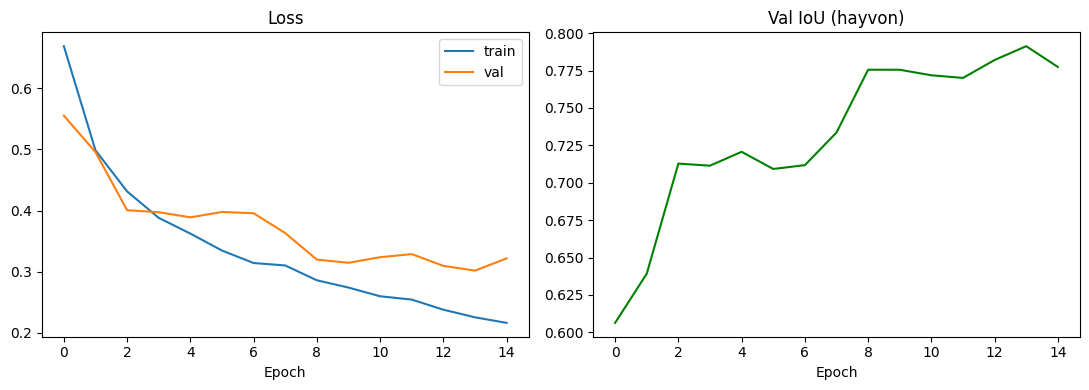

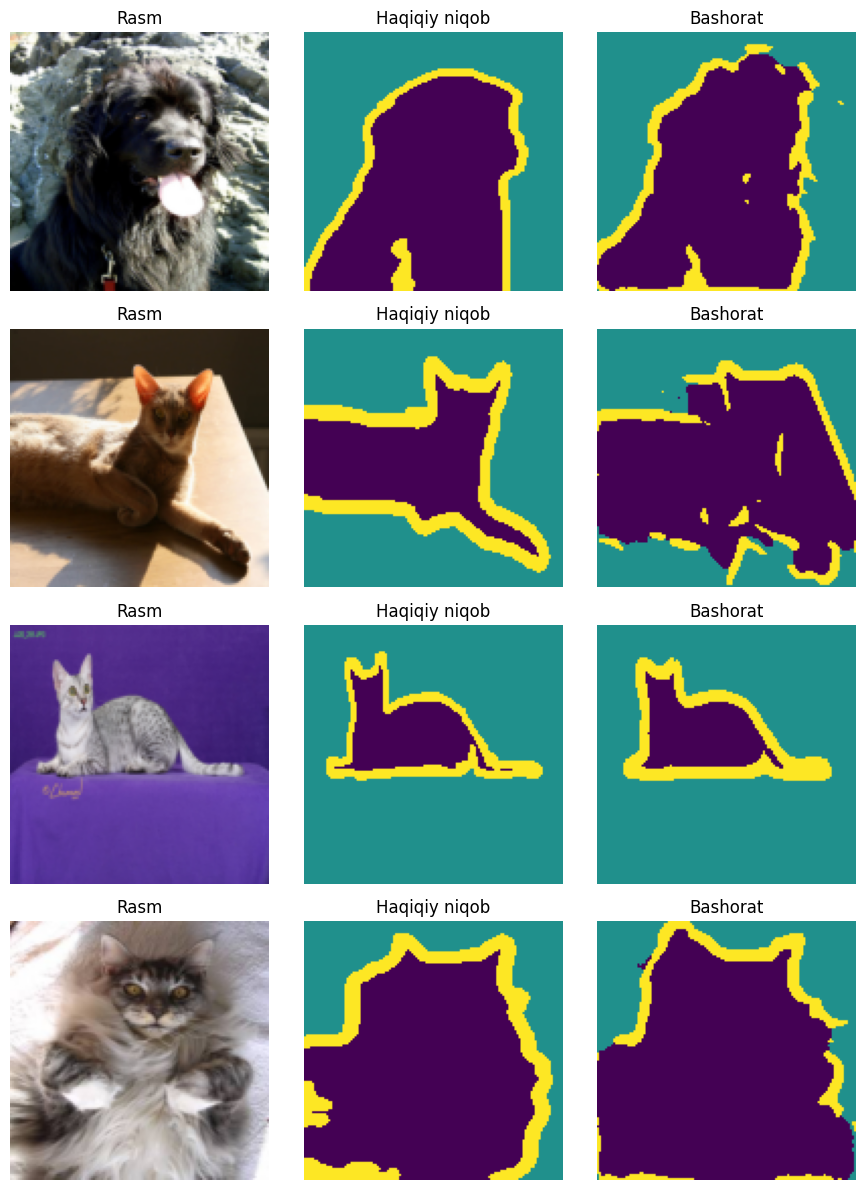

In [5]:
import matplotlib.pyplot as plt

# 1) Loss va IoU grafigi
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train"], label="train"); ax[0].plot(hist["val"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["iou"], color="green"); ax[1].set_title("Val IoU (hayvon)")
ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.savefig("curves.png", dpi=150); plt.show()

# 2) Rasm / haqiqiy niqob / bashorat
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
x, y = next(iter(val_dl))
with torch.no_grad():
    pred = model(x.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for i in range(4):
    axes[i, 0].imshow(x[i].permute(1, 2, 0)); axes[i, 0].set_title("Rasm")
    axes[i, 1].imshow(y[i]);    axes[i, 1].set_title("Haqiqiy niqob")
    axes[i, 2].imshow(pred[i]); axes[i, 2].set_title("Bashorat")
    for a in axes[i]: a.axis("off")
plt.tight_layout(); plt.savefig("predictions.png", dpi=150); plt.show()